# Análise descritiva das velas diárias da Binance Spot

Este notebook caracteriza os 40 pares cotados em USDT a partir dos CSVs brutos validados. Cada dia corresponde à data de abertura da vela em UTC. As estatísticas usam o recorte inclusivo da configuração. A primeira variação entre fechamentos exige dois dias dentro desse recorte. Os resultados desta análise se referem à amostra histórica selecionada por atividade e situação de negociação na Binance Spot.

A execução calcula a análise em memória. Para publicar CSVs e figuras, defina a variável de ambiente `TCC_DESCRIPTIVE_RUN_ID` com um identificador novo antes de iniciar o notebook. A página da decisão metodológica descreve como gerar Word e PDF a partir dessa execução.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap
from tcc_crypto import collection, config, results
from tcc_crypto.paths import ROOT, DescriptivePaths

settings = config.load_descriptive_config()
candles, diagnostics, scope, sources = collection.load_descriptive_candles()
symbols = scope["symbols"]
calendar = pd.date_range(settings["start"], settings["end"], tz="UTC", name="date_utc")
collection_start = pd.Timestamp(scope["collection"]["start_time_utc"])
collection_end = pd.Timestamp(scope["collection"]["end_time_utc"])
if calendar[0] < collection_start or calendar[-1] > collection_end:
    raise ValueError("O recorte deve estar contido no período solicitado da coleta.")

tables, figures = {}, {}
size = settings["rolling_returns"]
tail_low, tail_high = settings["tail_quantiles"]
low_support = settings["low_correlation_support"]
period_label = f"{calendar[0]:%d/%m/%Y} a {calendar[-1]:%d/%m/%Y} (UTC)"
source_label = "Fonte dos dados  ·  CSVs brutos da Binance Spot"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
blue, teal, orange = "#26588b", "#087f78", "#b8472d"

## Cobertura e integridade

As relações OHLC, os horários, os volumes e a contagem de negócios são verificados antes da análise. O calendário recebe categorias para dias com ou sem vela e distingue a vela válida encurtada da completa. Os limites do trecho observado são a primeira e a última vela válida dentro do recorte. A taxa no trecho usa todos os dias entre esses limites. A taxa no recorte usa todo o calendário comum. Dias inválidos são identificados mesmo quando caem fora do trecho válido.

In [2]:
panels, audit, coverage_records = {}, [], []
for symbol in symbols:
    checks = diagnostics[symbol].reindex(calendar)
    valid = checks["valid"].eq(True)
    seen = checks["valid"].notna()
    shortened = valid & checks["shortened_candle"].eq(True)
    available = calendar[valid]
    first, last = (available[0], available[-1]) if len(available) else (pd.NaT, pd.NaT)
    within = (calendar >= first) & (calendar <= last)
    state = pd.Series("no_observed_span", index=calendar, name=symbol)
    state.loc[calendar < first] = "before_first"
    state.loc[calendar > last] = "after_last"
    state.loc[within] = "internal_missing"
    state.loc[seen & ~valid] = "invalid"
    state.loc[valid] = "valid_full"
    state.loc[shortened] = "valid_shortened"

    panel = candles[symbol].reindex(calendar).where(valid, axis=0)
    panel["shortened"] = shortened
    panel["status"] = state
    panel["in_observed_span"] = within
    panels[symbol] = panel
    for date, status in state[state.isin(["invalid", "valid_shortened", "internal_missing"])].items():
        reason = checks.loc[date, "reason"] if status == "invalid" else status
        close_ms = candles[symbol]["close_time_ms"].get(date, np.nan)
        open_ms = candles[symbol]["open_time_ms"].get(date, np.nan)
        audit.append({"symbol": symbol, "date_utc": date, "status": status,
                      "reason": reason, "duration_ms": close_ms - open_ms + 1})
    coverage_records.append({
        "symbol": symbol, "first_valid_utc": first, "last_valid_utc": last,
        "calendar_days": len(calendar), "span_days": int(within.sum()),
        **{key: int(state.eq(key).sum()) for key in [
            "before_first", "after_last", "no_observed_span", "internal_missing",
            "invalid", "valid_shortened", "valid_full"
        ]},
        "invalid_in_span": int((within & state.eq("invalid")).sum()),
        "valid_days": int(valid.sum()), "coverage_calendar_pct": 100 * valid.mean(),
        "coverage_span_pct": 100 * valid.sum() / within.sum() if within.any() else np.nan,
    })

coverage = pd.DataFrame(coverage_records)
tables["coverage"] = coverage
tables["candle_exceptions"] = pd.DataFrame(
    audit, columns=["symbol", "date_utc", "status", "reason", "duration_ms"]
)
states = pd.DataFrame({symbol: panels[symbol]["status"] for symbol in symbols})
tables["coverage_calendar"] = states.reset_index()
observed_daily = states.isin(["valid_full", "valid_shortened"]).sum(axis=1)
tables["assets_per_day"] = observed_daily.rename("observed_assets").reset_index()
display(coverage[["symbol", "first_valid_utc", "valid_days", "coverage_span_pct"]].head(8).rename(columns={
    "symbol": "Par", "first_valid_utc": "Primeira vela válida (UTC)",
    "valid_days": "Velas válidas", "coverage_span_pct": "Cobertura no trecho (%)",
}))

,Par,Primeira vela válida (UTC),Velas válidas,Cobertura no trecho (%)
0,BTCUSDT,2019-07-01 00:00:00+00:00,2620,100.0
1,FLOKIUSDT,2023-05-05 00:00:00+00:00,1216,100.0
2,ETHUSDT,2019-07-01 00:00:00+00:00,2620,100.0
3,BONKUSDT,2023-12-15 00:00:00+00:00,992,100.0
4,SOLUSDT,2020-08-11 00:00:00+00:00,2213,100.0
5,XRPUSDT,2019-07-01 00:00:00+00:00,2620,100.0
6,SHIBUSDT,2021-05-10 00:00:00+00:00,1941,100.0
7,DOGEUSDT,2019-07-05 00:00:00+00:00,2616,100.0


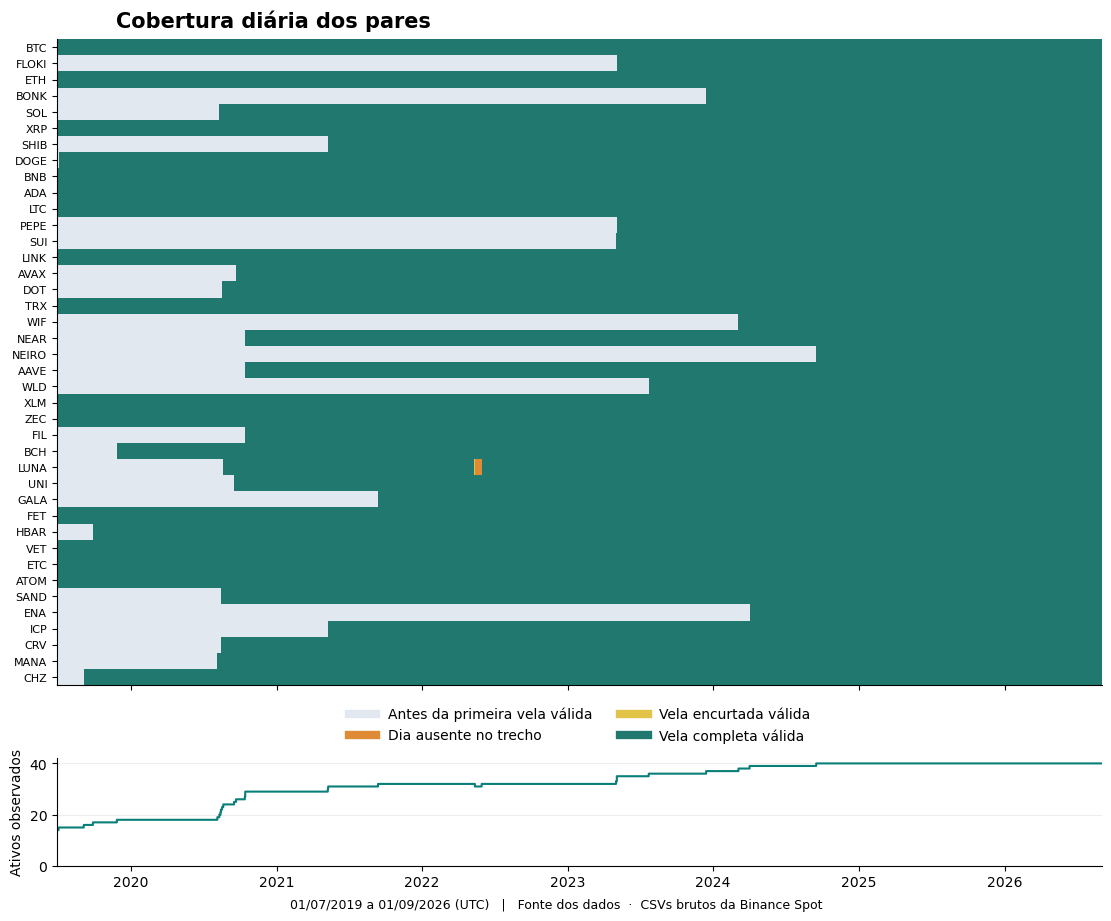

In [3]:
def finish(fig, name, title, *, show=False):
    fig.suptitle(title, x=0.10, ha="left", fontsize=15, fontweight="bold")
    fig.supxlabel(f"{period_label}   |   {source_label}", fontsize=9)
    figures[name] = fig
    if show:
        display(fig)
    plt.close(fig)

palette = {
    "before_first": ("Antes da primeira vela válida", "#e1e8ef"),
    "after_last": ("Após a última vela válida", "#acb8c5"),
    "no_observed_span": ("Sem trecho válido", "#828f9b"),
    "internal_missing": ("Dia ausente no trecho", "#df8a35"),
    "invalid": ("Vela inválida", "#a92f42"),
    "valid_shortened": ("Vela encurtada válida", "#e1c348"),
    "valid_full": ("Vela completa válida", "#20786f"),
}
state_codes = {name: i for i, name in enumerate(palette)}
fig, (timeline, count) = plt.subplots(
    2, 1, figsize=(11, 9.1), height_ratios=[6, 1], sharex=True, layout="constrained"
)
timeline.pcolormesh(
    calendar, np.arange(len(symbols)),
    states.apply(lambda column: column.map(state_codes)).to_numpy(dtype=int).T,
    cmap=ListedColormap([entry[1] for entry in palette.values()]),
    norm=BoundaryNorm(np.arange(-0.5, len(palette)), len(palette)),
    shading="nearest", rasterized=True,
)
timeline.set_yticks(np.arange(len(symbols)), [s.removesuffix("USDT") for s in symbols], fontsize=8)
timeline.invert_yaxis()
for name, (label, color) in palette.items():
    if states.eq(name).any().any():
        timeline.plot([], [], color=color, linewidth=6, label=label)
timeline.legend(loc="upper center", bbox_to_anchor=(0.5, -0.015), ncol=2, frameon=False)
count.step(calendar, observed_daily, where="mid", color=teal)
count.set(ylabel="Ativos observados", ylim=(0, len(symbols) + 2))
count.grid(axis="y", alpha=0.22)
finish(fig, "coverage", "Cobertura diária dos pares", show=True)

## Preços e variações

A abertura, a máxima, a mínima e o fechamento são medidos em USDT por unidade do ativo. O retorno simples é (100(C_t/C_{t-1}-1)), atribuído à data (t), e exige duas velas válidas em dias consecutivos. A amplitude é (100(H_t-L_t)/O_t). A volatilidade usa o desvio-padrão amostral do retorno em pontos percentuais, com pelo menos dois retornos. A série móvel exige uma sequência completa de retornos diários, equivalente a uma vela adicional no início da janela.

As estatísticas semestrais usam os dias do calendário civil. O semestre recebe marcações distintas para o recorte incompleto e para a ausência de cobertura válida em suas bordas. A contagem de dados ausentes nas estatísticas limita-se ao trecho observado. As lacunas internas têm contagem própria. Assimetria e curtose em excesso seguem os estimadores amostrais corrigidos. Medidas indefinidas ficam ausentes.

In [4]:
semester = pd.Series(
    calendar.year.astype(str) + "-H" + np.where(calendar.month <= 6, "1", "2"),
    index=calendar, name="semester"
)
semesters = list(semester.unique())
periods = [("overall", calendar)] + list(semester.groupby(semester, sort=False).groups.items())
price_fields = ["open", "high", "low", "close"]

def distribution(series):
    observed = series.dropna()
    quantiles = observed.quantile([tail_low, 0.25, 0.50, 0.75, tail_high], interpolation="linear")
    minimum, maximum = observed.min(), observed.max()
    sd, mean = observed.std(ddof=1), observed.mean()
    return {
        "n": len(observed), "mean": mean, "sample_sd": sd,
        "sample_variance": observed.var(ddof=1),
        "min": minimum, "tail_low": quantiles[tail_low], "q1": quantiles[0.25],
        "median": quantiles[0.50], "q3": quantiles[0.75], "tail_high": quantiles[tail_high],
        "max": maximum, "range": maximum - minimum,
        "iqr": quantiles[0.75] - quantiles[0.25],
        "sample_skew": observed.skew(), "fisher_excess_kurtosis": observed.kurt(),
    }

def prepare_daily(panel):
    daily = panel.copy()
    daily["return_pct"] = 100 * (daily["close"] / daily["close"].shift(1) - 1)
    daily["amplitude_pct"] = 100 * (daily["high"] - daily["low"]) / daily["open"]
    daily["moving_volatility_pp"] = daily["return_pct"].rolling(size, min_periods=size).std(ddof=1)
    daily["value_per_trade_usdt"] = daily["quote_asset_volume"] / daily["number_of_trades"].where(
        daily["number_of_trades"].gt(0)
    )
    return daily

daily_by_symbol = {symbol: prepare_daily(panel) for symbol, panel in panels.items()}
daily = pd.concat(daily_by_symbol, names=["symbol"]).reset_index()
tables["daily_metrics"] = daily[[
    "symbol", "date_utc", "status", "shortened", *price_fields, "quote_asset_volume",
    "number_of_trades", "return_pct", "amplitude_pct", "moving_volatility_pp",
    "value_per_trade_usdt"
]]
returns = daily.pivot(index="date_utc", columns="symbol", values="return_pct").reindex(columns=symbols)

def period_context(symbol, name, dates, data):
    valid_dates = data.index[data["close"].notna()]
    if name == "overall":
        partial = pd.NA
    else:
        year, half = name.split("-H")
        start = pd.Timestamp(f"{year}-{1 if half == '1' else 7:02d}-01", tz="UTC")
        end = start + pd.DateOffset(months=6) - pd.Timedelta(days=1)
        partial = bool(dates[0] != start or dates[-1] != end)
    return {
        "symbol": symbol, "period": name, "calendar_days": len(data),
        "calendar_partial_semester": partial,
        "coverage_partial": bool(not len(valid_dates) or valid_dates[0] != dates[0]
                                 or valid_dates[-1] != dates[-1]),
        "observed_candles": len(valid_dates), "span_days": int(data["in_observed_span"].sum()),
        "internal_missing_days": int(data["status"].eq("internal_missing").sum()),
    }

def activity_summary(data):
    volume, trades = data["quote_asset_volume"], data["number_of_trades"]
    volume_total, trades_total = volume.sum(min_count=1), trades.sum(min_count=1)
    return {
        "volume_total_usdt": volume_total,
        "volume_daily_median_usdt": volume.median(),
        "trades_total": trades_total, "trades_daily_median": trades.median(),
        "volume_zero_days": int(volume.eq(0).sum()), "trades_zero_days": int(trades.eq(0).sum()),
        "days_with_defined_trade_value": int(data["value_per_trade_usdt"].count()),
        "daily_median_value_per_trade_usdt": data["value_per_trade_usdt"].median(),
        "weighted_value_per_trade_usdt": volume_total / trades_total if trades_total > 0 else np.nan,
    }

price_records, movement_records, activity_records, sensitivity_records = [], [], [], []
for symbol, frame in daily_by_symbol.items():
    for name, dates in periods:
        data = frame.loc[dates]
        keys = period_context(symbol, name, dates, data)
        for field in [*price_fields, "quote_asset_volume"]:
            metrics = distribution(data[field])
            price_records.append({
                **keys, "field": field, **metrics, "missing_in_span": keys["span_days"] - metrics["n"],
                "coefficient_of_variation": (metrics["sample_sd"] / metrics["mean"]
                                             if metrics["mean"] > 0 else np.nan),
                "zero_count": int(data[field].eq(0).sum()) if field == "quote_asset_volume" else pd.NA,
                "zero_share": (data[field].eq(0).sum() / metrics["n"]
                               if field == "quote_asset_volume" and metrics["n"] else np.nan),
                "total": data[field].sum(min_count=1) if field == "quote_asset_volume" else np.nan,
            })
        for field in ["return_pct", "amplitude_pct"]:
            x = data[field].dropna()
            record = {**keys, "field": field, **distribution(x)}
            if field == "return_pct":
                record.update({f"{label}_pct": 100 * share.mean() for label, share in
                               [("positive", x.gt(0)), ("negative", x.lt(0)), ("zero", x.eq(0))]})
            movement_records.append(record)
        activity_records.append({**keys, **activity_summary(data)})
        if data["shortened"].any():
            for label, sample in [("all_valid", data), ("full_only", data.loc[~data["shortened"]])]:
                sensitivity_records.append({
                    **keys, "sample": label, "observed_candles": int(sample["close"].count()),
                    **activity_summary(sample),
                    **{f"amplitude_{key}": value for key, value in distribution(sample["amplitude_pct"]).items()}
                })
tables["price_volume_statistics"] = pd.DataFrame(price_records)
tables["movement_statistics"] = movement = pd.DataFrame(movement_records)
tables["trading_activity"] = activity = pd.DataFrame(activity_records)
tables["shortened_candle_sensitivity"] = pd.DataFrame(
    sensitivity_records,
    columns=list(dict.fromkeys(key for row in sensitivity_records for key in row))
    if sensitivity_records else [
        *keys, "sample", *activity_summary(data),
        *(f"amplitude_{key}" for key in distribution(data["amplitude_pct"])),
    ],
)

### Rastreabilidade dos extremos

Empates são preservados. Cada retorno extremo tem os dois fechamentos, os dois horários de abertura em milissegundos e o caminho do arquivo correspondente. Os preços usados são confrontados com as linhas originais carregadas antes do alinhamento. A tabela inclui extremos no recorte inteiro e em cada semestre.

In [5]:
extreme_records = []
for symbol, frame in daily_by_symbol.items():
    source = candles[symbol]
    for name, dates in periods:
        data = frame.loc[dates]
        for field in [*price_fields, "return_pct", "amplitude_pct"]:
            observed = data[field].dropna()
            if observed.empty:
                continue
            for extreme, value in [("min", observed.min()), ("max", observed.max())]:
                for date in observed.index[observed.eq(value)]:
                    current = source.loc[date]
                    previous = (source.loc[date - pd.Timedelta(days=1)]
                                if field == "return_pct" else None)
                    np.testing.assert_array_equal(
                        current[price_fields].to_numpy(dtype=float),
                        frame.loc[date, price_fields].to_numpy(dtype=float)
                    )
                    if field == "return_pct":
                        assert previous["close"] == frame.loc[date - pd.Timedelta(days=1), "close"]
                    extreme_records.append({
                        "symbol": symbol, "period": name, "field": field, "extreme": extreme,
                        "date_utc": date, "value": value, "source": sources[symbol]["raw"],
                        "open_time_ms": int(current["open_time_ms"]),
                        "close_time_ms": int(current["close_time_ms"]),
                        **{price: current[price] for price in price_fields},
                        "previous_open_time_ms": int(previous["open_time_ms"]) if previous is not None else pd.NA,
                        "previous_close": previous["close"] if previous is not None else np.nan,
                    })
tables["extremes"] = pd.DataFrame(extreme_records)
tables["extremes"]["previous_open_time_ms"] = tables["extremes"]["previous_open_time_ms"].astype("Int64")

## Evolução dos preços e distribuição dos retornos

Os painéis de séries usam o mesmo calendário e escalas verticais próprias. Preços são rotulados em USDT em escala logarítmica. A mesma mudança proporcional tem a mesma altura dentro de um painel. A função de distribuição empírica mostra a porcentagem de observações abaixo ou no nível de cada retorno. Ela apresenta todos os valores, com eixo horizontal simétrico logarítmico e faixa linear perto de zero para preservar a legibilidade das caudas.

In [6]:
fig, axes = plt.subplots(8, 5, figsize=(15, 17), sharex=True, layout="constrained")
for axis, symbol in zip(axes.flat, symbols):
    data = daily_by_symbol[symbol]
    axis.plot(calendar, data["open"], color=blue, alpha=0.65, linewidth=0.65, label="Abertura")
    axis.plot(calendar, data["close"], color=orange, linewidth=0.55, label="Fechamento")
    axis.set(title=symbol.removesuffix("USDT"), yscale="log", xlim=(calendar[0], calendar[-1]))
    axis.tick_params(labelsize=8)
    axis.grid(axis="y", alpha=0.20)
    if symbol == symbols[0]:
        axis.legend(fontsize=7, loc="upper left", frameon=False)
fig.supylabel("Preço (USDT por unidade do ativo, escala logarítmica)", fontsize=10)
finish(fig, "prices", "Abertura e fechamento por ativo")

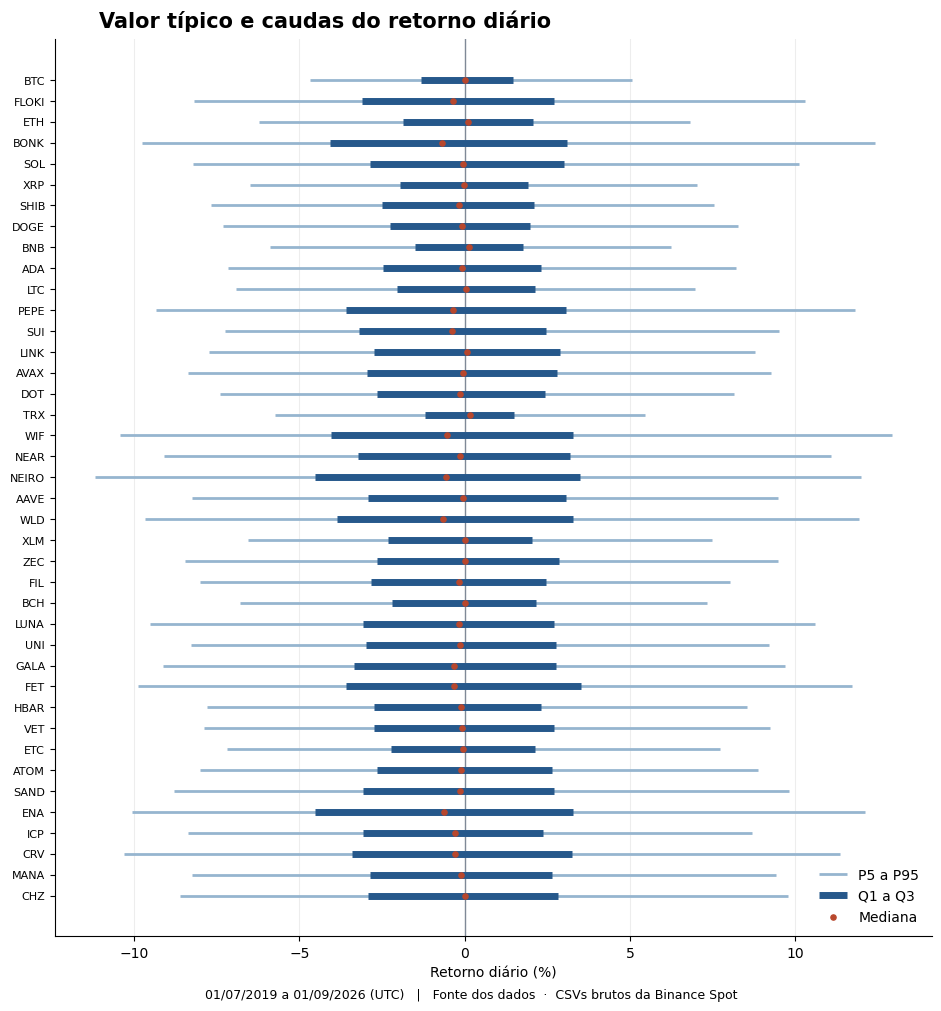

In [7]:
overall_returns = movement.loc[movement["period"].eq("overall") & movement["field"].eq("return_pct")]
x = overall_returns.set_index("symbol").loc[symbols].iloc[::-1]
y = np.arange(len(x))
fig, ax = plt.subplots(figsize=(9.3, 10), layout="constrained")
ax.axvline(0, color="#7f8997", linewidth=1)
ax.hlines(y, x["tail_low"], x["tail_high"], color="#96b5cf", linewidth=2,
          label=f"P{tail_low:.0%}".replace("%", "") + f" a P{tail_high:.0%}".replace("%", ""))
ax.hlines(y, x["q1"], x["q3"], color=blue, linewidth=5, label="Q1 a Q3")
ax.scatter(x["median"], y, c=orange, s=14, zorder=3, label="Mediana")
ax.set_yticks(y, [s.removesuffix("USDT") for s in x.index], fontsize=8)
ax.set_xlabel("Retorno diário (%)")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", alpha=0.22)
finish(fig, "return_intervals", "Valor típico e caudas do retorno diário", show=True)

In [8]:
fig, axes = plt.subplots(8, 5, figsize=(15, 17), sharex=True, sharey=True, layout="constrained")
bound = max(2, float(returns.abs().max().max()))
for axis, symbol in zip(axes.flat, symbols):
    values = np.sort(returns[symbol].dropna())
    if len(values):
        axis.step(np.r_[-bound, values, bound], np.r_[0, np.arange(1, len(values) + 1) / len(values) * 100, 100],
                  where="post", color=teal, linewidth=1)
    axis.axvline(0, color="#838e99", linewidth=0.7)
    axis.set(title=symbol.removesuffix("USDT"), xscale="symlog", xlim=(-bound, bound), ylim=(0, 102))
    axis.set_xscale("symlog", linthresh=2)
    axis.tick_params(labelsize=7)
    axis.grid(alpha=0.15)
fig.supylabel("Frequência acumulada (%)", fontsize=10)
finish(fig, "return_distributions", "Distribuições empíricas dos retornos diários")

## Volatilidade no tempo

O semestre de referência é o da vela final de cada retorno. A janela móvel atravessa a fronteira entre semestres quando há dados consecutivos. As contagens semestrais correspondentes estão na tabela de estatísticas de movimento. Cinza indica uma combinação sem estimativa.

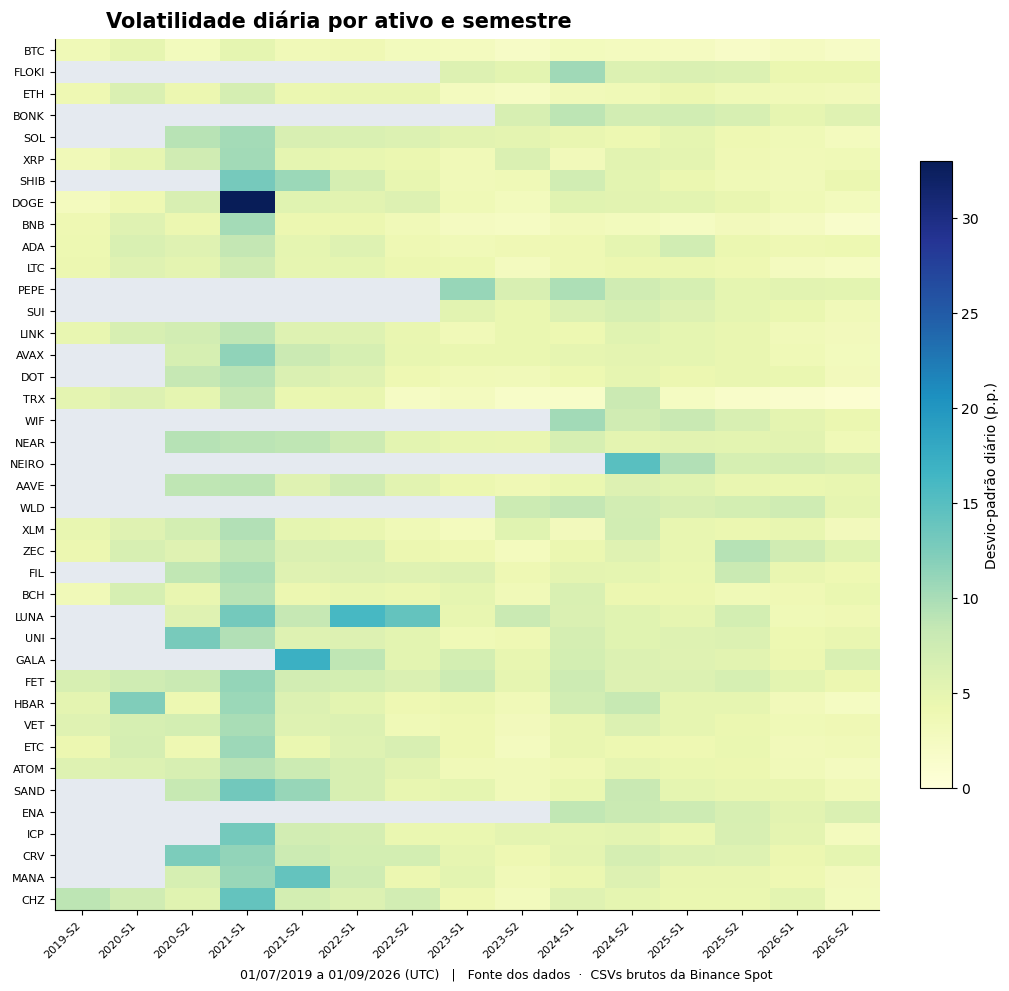

In [9]:
volatility = movement.loc[movement["field"].eq("return_pct") & movement["period"].ne("overall")]
volatility_matrix = volatility.pivot(index="symbol", columns="period", values="sample_sd").reindex(
    index=symbols, columns=semesters
)
tables["volatility_semester_n"] = volatility.pivot(index="symbol", columns="period", values="n").reindex(
    index=symbols, columns=semesters
).reset_index()
fig, axis = plt.subplots(figsize=(10, 9.8), layout="constrained")
image = axis.imshow(
    volatility_matrix, aspect="auto", interpolation="nearest",
    cmap=plt.get_cmap("YlGnBu").with_extremes(bad="#e5eaf0"), vmin=0
)
axis.set_xticks(np.arange(len(semesters)), [s.replace("H", "S") for s in semesters],
                rotation=45, ha="right", fontsize=8)
axis.set_yticks(np.arange(len(symbols)), [s.removesuffix("USDT") for s in symbols], fontsize=8)
fig.colorbar(image, ax=axis, label="Desvio-padrão diário (p.p.)", shrink=0.72)
finish(fig, "volatility_semester", "Volatilidade diária por ativo e semestre", show=True)

In [10]:
fig, axes = plt.subplots(8, 5, figsize=(15, 17), sharex=True, layout="constrained")
for axis, symbol in zip(axes.flat, symbols):
    axis.plot(calendar, daily_by_symbol[symbol]["moving_volatility_pp"], color=teal, linewidth=0.8)
    axis.set(title=symbol.removesuffix("USDT"), xlim=(calendar[0], calendar[-1]))
    axis.set_ylim(bottom=0)
    axis.grid(axis="y", alpha=0.20)
    axis.tick_params(labelsize=8)
fig.supylabel("Volatilidade diária (p.p.)", fontsize=10)
finish(fig, "volatility_rolling", f"Volatilidade móvel de {size} retornos consecutivos")

## Volume e atividade de negociação

O volume é informado pela Binance em USDT. A razão diária entre volume e número de negócios indica o valor médio por negócio. Para um semestre, a razão entre os totais representa a média ponderada pelos negócios. A mediana dos valores diários dá peso igual a cada dia com denominador positivo. As curvas de igual volume mostram combinações com o mesmo produto. O gráfico em eixos logarítmicos apresenta somente dias com quantidade e valor médio positivos. As tabelas incluem também as contagens de zeros e as razões indefinidas.

In [11]:
fig, axes = plt.subplots(8, 5, figsize=(15, 17), sharex=True, layout="constrained")
for axis, symbol in zip(axes.flat, symbols):
    axis.plot(calendar, daily_by_symbol[symbol]["quote_asset_volume"] / 1e9, color=blue, linewidth=0.65)
    axis.set(title=symbol.removesuffix("USDT"), xlim=(calendar[0], calendar[-1]))
    axis.set_ylim(bottom=0)
    axis.tick_params(labelsize=8)
    axis.grid(axis="y", alpha=0.22)
fig.supylabel("Volume diário (bilhões de USDT)", fontsize=10)
finish(fig, "volume", "Volume diário negociado por ativo")

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 9.5), sharey=True, layout="constrained")
for axis, field, label in zip(axes, ["volume_daily_median_usdt", "trades_daily_median"],
                             ["Volume diário mediano (USDT)", "Quantidade diária mediana"]):
    matrix = activity.loc[activity["period"].ne("overall")].pivot(
        index="symbol", columns="period", values=field
    ).reindex(index=symbols, columns=semesters)
    img = axis.imshow(np.log10(matrix.where(matrix.gt(0))), aspect="auto", interpolation="nearest",
                      cmap=plt.get_cmap("YlGnBu").with_extremes(bad="#e5eaf0"))
    axis.set_title(label, loc="left", fontsize=10)
    axis.set_xticks(np.arange(len(semesters)), [s.replace("H", "S") for s in semesters],
                    rotation=45, ha="right", fontsize=8)
    axis.set_yticks(np.arange(len(symbols)), [s.removesuffix("USDT") for s in symbols], fontsize=8)
    fig.colorbar(img, ax=axis, label="log₁₀ da mediana", shrink=0.70)
finish(fig, "activity_semester", "Atividade diária típica em cada semestre")

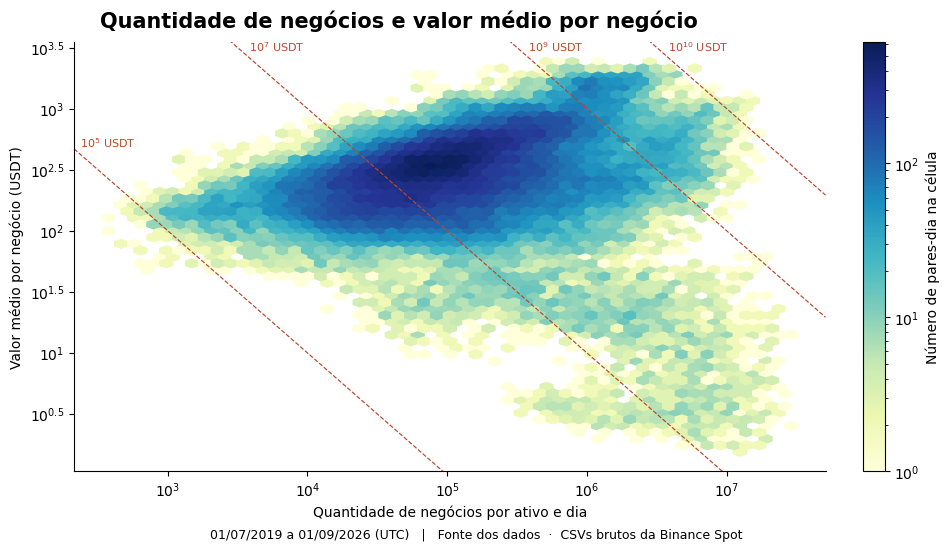

In [13]:
activity_points = daily.loc[daily["number_of_trades"].gt(0) & daily["value_per_trade_usdt"].gt(0)]
fig, axis = plt.subplots(figsize=(9.4, 5.4), layout="constrained")
density = axis.hexbin(np.log10(activity_points["number_of_trades"]),
                      np.log10(activity_points["value_per_trade_usdt"]),
                      gridsize=53, mincnt=1, bins="log", cmap="YlGnBu")
axis.set(xlabel="Quantidade de negócios por ativo e dia", ylabel="Valor médio por negócio (USDT)")
bounds = axis.get_ylim()
line_x = np.array(axis.get_xlim())
for power in (5, 7, 9, 10):
    axis.plot(line_x, power - line_x, "--", color=orange, linewidth=0.85)
    anchor = max(line_x[0] + 0.04, power - bounds[1] + 0.12)
    if anchor < line_x[1] and bounds[0] < power - anchor < bounds[1]:
        axis.text(anchor, power - anchor + 0.05, f"10$^{{{power}}}$ USDT",
                  color=orange, fontsize=8)
axis.set(xlim=line_x, ylim=bounds)
for scale in (axis.xaxis, axis.yaxis):
    scale.set_major_formatter(plt.FuncFormatter(lambda value, _: f"$10^{{{value:g}}}$"))
fig.colorbar(density, ax=axis, label="Número de pares-dia na célula")
finish(fig, "activity_isovolume", "Quantidade de negócios e valor médio por negócio", show=True)

## Dependência entre os ativos

Cada par de ativos é alinhado pelas datas de retornos válidos. Pearson usa os valores e Spearman aplica Pearson aos postos calculados dentro da própria amostra, com postos médios em empates. Os coeficientes ficam ausentes quando o cálculo é indefinido. A amostra comum de todos os ativos é a interseção efetiva das datas válidas. A tabela inclui a primeira e a última data de cada comparação, que podem delimitar um intervalo com lacunas.

As duas matrizes de cada amostra usam a mesma ordem de ativos e escala fixa de −1 a +1. O gráfico de contagens explicita o suporte, e as células com suporte reduzido recebem uma marca sobreposta.

In [14]:
def paired_correlation(sample):
    if len(sample) < 2 or sample.iloc[:, 0].nunique() < 2 or sample.iloc[:, 1].nunique() < 2:
        return np.nan, np.nan
    return (sample.iloc[:, 0].corr(sample.iloc[:, 1]),
            sample.rank().iloc[:, 0].corr(sample.rank().iloc[:, 1]))

common = returns.dropna(how="any")
pairs, matrices = [], {}
for label, sample in [("pairwise", returns), ("common", common)]:
    pearson = pd.DataFrame(np.nan, index=symbols, columns=symbols, dtype=float)
    spearman = pearson.copy()
    counts = pd.DataFrame(0, index=symbols, columns=symbols, dtype=int)
    for i, left in enumerate(symbols):
        for right in symbols[i:]:
            pair = sample[[left, right]].dropna()
            n = len(pair)
            p, s = paired_correlation(pair)
            pearson.loc[left, right] = pearson.loc[right, left] = np.clip(p, -1, 1)
            spearman.loc[left, right] = spearman.loc[right, left] = np.clip(s, -1, 1)
            counts.loc[left, right] = counts.loc[right, left] = n
            if left != right:
                pairs.append({
                    "sample": label, "symbol_a": left, "symbol_b": right, "n": n,
                    "first_date_utc": pair.index.min(), "last_date_utc": pair.index.max(),
                    "low_support": n < low_support,
                    "pearson": pearson.loc[left, right], "spearman": spearman.loc[left, right],
                })
    matrices[label] = {"pearson": pearson, "spearman": spearman, "n": counts}
    for name, matrix in matrices[label].items():
        tables[f"correlation_{label}_{name}"] = matrix.rename_axis("symbol").reset_index()
tables["correlation_pairs"] = pair_table = pd.DataFrame(pairs)
tables["correlation_common_dates"] = pd.DataFrame({"date_utc": common.index})

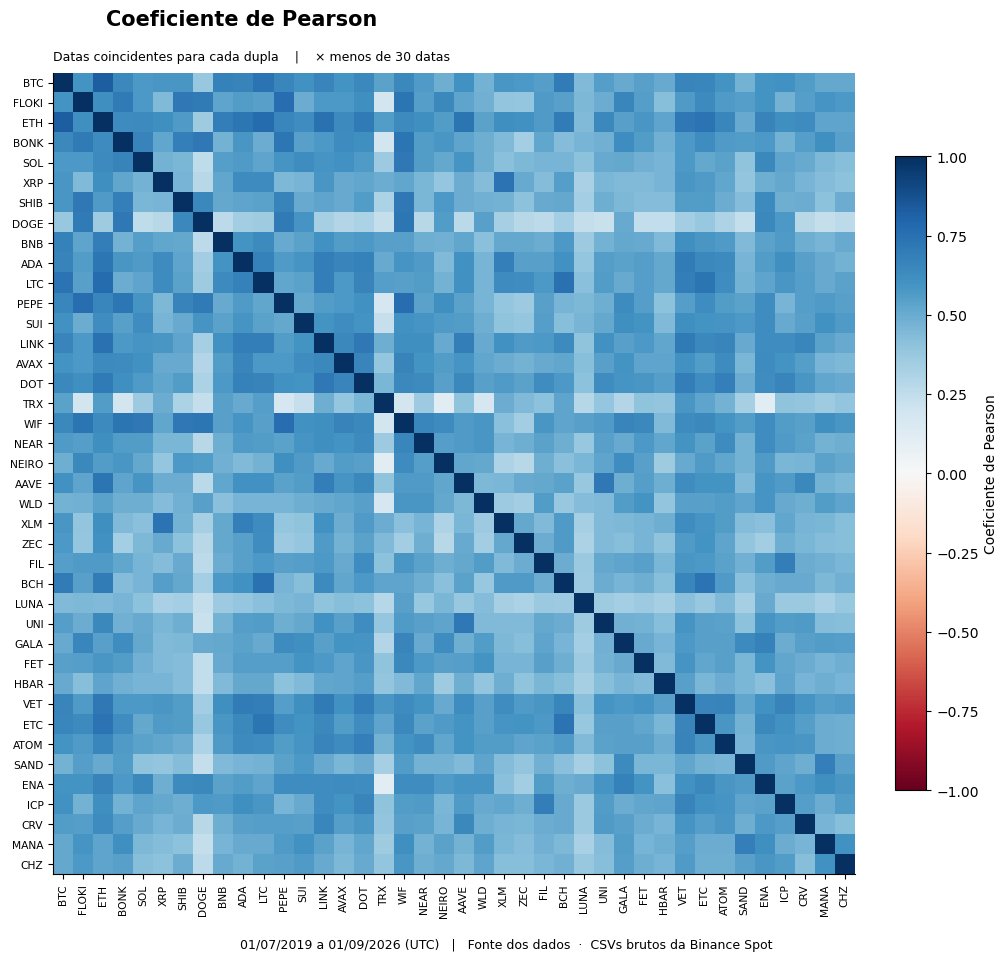

In [15]:
common_label = (
    f"Amostra comum  ·  {common.index.min():%d/%m/%Y} a {common.index.max():%d/%m/%Y}  ·  {len(common)} datas"
    if len(common) else "Amostra comum sem datas disponíveis"
)
labels = [symbol.removesuffix("USDT") for symbol in symbols]
for sample, metrics in matrices.items():
    subtitle = "Datas coincidentes para cada dupla" if sample == "pairwise" else common_label
    for key, values in metrics.items():
        count_map = key == "n"
        fig, axis = plt.subplots(figsize=(10.0, 9.5), layout="constrained")
        color = plt.get_cmap("YlGnBu" if count_map else "RdBu").with_extremes(bad="#dbe0e8")
        bounds = {"vmin": 0} if count_map else {"vmin": -1, "vmax": 1}
        image = axis.imshow(values, interpolation="nearest", cmap=color, **bounds)
        axis.set_xticks(np.arange(len(labels)), labels, rotation=90, fontsize=7.7)
        axis.set_yticks(np.arange(len(labels)), labels, fontsize=7.7)
        text = "Número de datas em comum" if count_map else f"Coeficiente de {key.capitalize()}"
        fig.colorbar(image, ax=axis, shrink=0.73, label=text)
        if not count_map:
            rows, columns = np.where(metrics["n"].to_numpy() < low_support)
            axis.scatter(columns, rows, s=8, c="#171f28", marker="x")
        axis.set_title(subtitle + ("" if count_map else f"    |    × menos de {low_support} datas"),
                       fontsize=9, loc="left", pad=9)
        finish(fig, f"correlation_{sample}_{key}", text, show=sample == "pairwise" and key == "pearson")

## Descontinuidade de LUNAUSDT

A maior lacuna interna identificada nos arquivos brutos delimita dois trechos para a leitura dos níveis de preço. Os extremos ficam no trecho onde ocorreram. As duas séries usam escalas verticais próprias e as datas no título indicam o limite de cada trecho.

In [16]:
luna = daily_by_symbol["LUNAUSDT"]
luna_dates = luna.index[luna["close"].notna()]
luna_gaps = luna_dates.to_series().diff().dropna()
after_gap = luna_gaps.idxmax()
before_gap = after_gap - luna_gaps.loc[after_gap]
assert (after_gap - before_gap).days > 1, "A descontinuidade de LUNAUSDT requer inspeção."
luna_pieces = [("before_gap", luna.loc[luna_dates[0]:before_gap]), ("after_gap", luna.loc[after_gap:luna_dates[-1]])]
tables["luna_segments"] = luna_segments = pd.DataFrame([
    {"segment": label, "start_utc": sample.index[0], "end_utc": sample.index[-1],
     "gap_days": (after_gap - before_gap).days - 1,
     **distribution(sample["close"])}
    for label, sample in luna_pieces
])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.7), layout="constrained")
for axis, heading, (_, sample) in zip(axes, ["Antes da lacuna", "Depois da lacuna"], luna_pieces):
    axis.plot(sample.index, sample["close"], color=blue, linewidth=0.9)
    axis.set(yscale="log", xlim=(sample.index[0], sample.index[-1]),
             title=f"{heading}  ·  {sample.index[0]:%d/%m/%Y} a {sample.index[-1]:%d/%m/%Y}")
    axis.title.set_fontsize(9)
    axis.grid(axis="y", alpha=0.22)
    axis.tick_params(axis="x", labelrotation=30, labelsize=8)
fig.supylabel("Fechamento (USDT, escala logarítmica)", fontsize=10)
finish(fig, "luna_segments", "Trajetórias de LUNAUSDT em torno da lacuna")

## Amostras e conferências

O diagrama documenta como o calendário auditado dá origem às amostras. As checagens reconciliam a quantidade de velas, o número de retornos e o suporte das matrizes antes da publicação. A tabela de síntese registra as medidas transversais citadas no texto da monografia.

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
ax.axis("off")
boxes = [
    (0.13, 0.55, "CSVs brutos\n+ metadados", "#edf3fa"),
    (0.36, 0.55, "Validação e\ncalendário UTC", "#edf3fa"),
    (0.65, 0.72, "Velas válidas\nobservadas", "#e9f6f2"),
    (0.65, 0.32, "Fechamentos válidos\nem dias consecutivos", "#e9f6f2"),
    (0.89, 0.72, "OHLC, amplitude\ne atividade", "#fbf1e8"),
    (0.89, 0.32, "Retornos, volatilidade\ne correlação", "#fbf1e8"),
]
for x, y, label, fill in boxes:
    ax.text(x, y, label, transform=ax.transAxes, ha="center", va="center", fontsize=11,
            bbox={"boxstyle": "round,pad=0.65", "facecolor": fill, "edgecolor": "#698399"})
for left, right in [((0.22, 0.55), (0.28, 0.55)),
                    ((0.45, 0.55), (0.55, 0.72)), ((0.45, 0.55), (0.53, 0.32)),
                    ((0.74, 0.72), (0.80, 0.72)), ((0.77, 0.32), (0.79, 0.32))]:
    ax.annotate("", xy=right, xytext=left, xycoords=ax.transAxes,
                arrowprops={"arrowstyle": "->", "color": "#456a83", "linewidth": 1.5})
finish(fig, "workflow", "Das velas brutas às amostras de análise")

In [18]:
pd.testing.assert_series_equal(
    daily.groupby("symbol")["close"].count().reindex(symbols),
    coverage.set_index("symbol")["valid_days"], check_names=False
)
assert int(coverage["valid_days"].sum()) == int(observed_daily.sum())
covered = coverage["valid_days"] + coverage["internal_missing"] + coverage["invalid_in_span"]
assert covered.eq(coverage["span_days"]).all()
status_columns = list(palette)
assert coverage[status_columns].sum(axis=1).eq(coverage["calendar_days"]).all()
assert (daily["moving_volatility_pp"].notna() <= daily["return_pct"].notna()).all()
assert not returns.iloc[0].notna().any()
for record in overall_returns.itertuples():
    symbol_returns = returns[record.symbol]
    assert record.n == symbol_returns.count()
    closing = daily_by_symbol[record.symbol]["close"].notna()
    assert symbol_returns.notna().eq(closing & closing.shift(fill_value=False)).all()
    total_semesters = volatility.loc[volatility["symbol"].eq(record.symbol), "n"].sum()
    assert record.n == total_semesters
for matrix_set in matrices.values():
    for matrix in matrix_set.values():
        np.testing.assert_allclose(matrix.to_numpy(), matrix.to_numpy().T, equal_nan=True)
present = returns.notna().astype(int)
np.testing.assert_array_equal(matrices["pairwise"]["n"], present.T @ present)
assert matrices["common"]["n"].eq(len(common)).all().all()
assert len(pair_table) == len(symbols) * (len(symbols) - 1)
assert set(tables["extremes"]["symbol"]) == set(symbols)

paired = pair_table.loc[pair_table["sample"].eq("pairwise")]
common_pairs = pair_table.loc[pair_table["sample"].eq("common")]
both = paired.merge(common_pairs, on=["symbol_a", "symbol_b"], suffixes=("_pairwise", "_common"))
comparable = both.loc[~both["low_support_pairwise"] & ~both["low_support_common"]]
luna_short = luna.loc[luna["shortened"]]
highest_volume = daily.loc[daily["quote_asset_volume"].idxmax()]
summary = {
    "symbols": len(symbols), "calendar_days": len(calendar),
    "valid_candles": int(coverage["valid_days"].sum()),
    "invalid_candles": int(coverage["invalid"].sum()),
    "shortened_candles": int(coverage["valid_shortened"].sum()),
    "internal_missing_days": int(coverage["internal_missing"].sum()),
    "pre_first_days": int(coverage["before_first"].sum()),
    "post_last_days": int(coverage["after_last"].sum()),
    "first_day_assets": int(observed_daily.iloc[0]), "last_day_assets": int(observed_daily.iloc[-1]),
    "return_count": int(returns.count().sum()),
    "median_asset_volatility_pp": overall_returns["sample_sd"].median(),
    "median_asset_return_pct": overall_returns["median"].median(),
    "median_asset_p05_pct": overall_returns["tail_low"].median(),
    "median_asset_p95_pct": overall_returns["tail_high"].median(),
    "pairs_count": len(paired), "pairs_n_min": int(paired["n"].min()),
    "pairs_n_max": int(paired["n"].max()), "pairs_low_support": int(paired["low_support"].sum()),
    "pairwise_pearson_median": paired.loc[~paired["low_support"], "pearson"].median(),
    "pairwise_spearman_median": paired.loc[~paired["low_support"], "spearman"].median(),
    "common_pearson_median": common_pairs.loc[~common_pairs["low_support"], "pearson"].median(),
    "common_spearman_median": common_pairs.loc[~common_pairs["low_support"], "spearman"].median(),
    "common_dates": len(common), "common_first_utc": common.index.min(),
    "common_last_utc": common.index.max(),
    "median_abs_pearson_change": (comparable["pearson_common"] - comparable["pearson_pairwise"]).abs().median(),
    "highest_volume_symbol": highest_volume["symbol"], "highest_volume_date_utc": highest_volume["date_utc"],
    "luna_short_days": len(luna_short), "luna_gap_start_utc": before_gap + pd.Timedelta(days=1),
    "luna_gap_end_utc": after_gap - pd.Timedelta(days=1),
}
tables["study_summary"] = pd.DataFrame([summary])
display(pd.DataFrame({
    "Indicador": ["Pares", "Velas válidas", "Retornos diários", "Duplas", "Datas comuns aos 40 pares"],
    "Valor": [summary[key] for key in ("symbols", "valid_candles", "return_count", "pairs_count", "common_dates")],
}))

,Indicador,Valor
0,Pares,40
1,Velas válidas,84867
2,Retornos diários,84826
3,Duplas,780
4,Datas comuns aos 40 pares,715


In [19]:
run_id = os.environ.get("TCC_DESCRIPTIVE_RUN_ID")
if run_id:
    paths = DescriptivePaths(ROOT, run_id)
    manifest = results.publish_descriptive_analysis(paths, settings, scope, sources, tables, figures)
    print(f"Evidências publicadas em {manifest.relative_to(ROOT)}")
else:
    print("Cálculo concluído em memória. Defina TCC_DESCRIPTIVE_RUN_ID para publicar os arquivos.")

Evidências publicadas em outputs/exploration/daily_candles_monograph_2026-11-23/manifest.json
